In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

file_path = Path(
    r"C:\Users\kavya\Rocket League Skillshots\dataset"
    r"\rocket+league+skillshots\rocket_league_skillshots.data"
)

df = pd.read_csv(file_path, sep=None, engine="python")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset loaded successfully!
Dataset shape: (7190, 19)

Columns:
['BallAcceleration', 'Time', 'DistanceWall', 'DistanceCeil', 'DistanceBall', 'PlayerSpeed', 'BallSpeed', 'up', 'accelerate', 'slow', 'goal', 'left', 'boost', 'camera', 'down', 'right', 'slide', 'jump', 'Unnamed: 18']


,BallAcceleration,Time,DistanceWall,DistanceCeil,DistanceBall,PlayerSpeed,BallSpeed,up,accelerate,slow,goal,left,boost,camera,down,right,slide,jump,Unnamed: 18
0,6.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1636.798772,0.000000,3498.01,2012.98,299.668270,104267.426232,99035.849337,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,NaN
2,3198.029397,0.138893,3494.08,2012.98,229.896780,124248.031988,102233.878734,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,NaN
3,0.000000,0.173617,3494.08,2012.98,237.350599,124248.031988,102968.358990,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,NaN
4,9914.766242,0.312510,3500.08,2012.98,151.880921,115248.016009,112883.125231,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,NaN


In [2]:
print("Column names:")
for column in df.columns:
    print(repr(column))

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

Column names:
'BallAcceleration'
'Time'
'DistanceWall'
'DistanceCeil'
'DistanceBall'
'PlayerSpeed'
'BallSpeed'
'up'
'accelerate'
'slow'
'goal'
'left'
'boost'
'camera'
'down'
'right'
'slide'
'jump'
'Unnamed: 18'

Data types:
BallAcceleration    float64
Time                float64
DistanceWall        float64
DistanceCeil        float64
DistanceBall        float64
PlayerSpeed         float64
BallSpeed           float64
up                  float64
accelerate          float64
slow                float64
goal                float64
left                float64
boost               float64
camera              float64
down                float64
right               float64
slide               float64
jump                float64
Unnamed: 18         float64
dtype: object

First 5 rows:


,BallAcceleration,Time,DistanceWall,DistanceCeil,DistanceBall,PlayerSpeed,BallSpeed,up,accelerate,slow,goal,left,boost,camera,down,right,slide,jump,Unnamed: 18
0,6.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1636.798772,0.000000,3498.01,2012.98,299.668270,104267.426232,99035.849337,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,NaN
2,3198.029397,0.138893,3494.08,2012.98,229.896780,124248.031988,102233.878734,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,NaN
3,0.000000,0.173617,3494.08,2012.98,237.350599,124248.031988,102968.358990,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,NaN
4,9914.766242,0.312510,3500.08,2012.98,151.880921,115248.016009,112883.125231,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,NaN


In [3]:
# Remove columns that are completely empty
df = df.dropna(axis=1, how="all")

# Remove leading/trailing spaces from column names
df.columns = df.columns.str.strip()

print("Updated dataset shape:", df.shape)
print("\nRemaining columns:")
print(df.columns.tolist())

print("\nMissing values per column:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Updated dataset shape: (7190, 18)

Remaining columns:
['BallAcceleration', 'Time', 'DistanceWall', 'DistanceCeil', 'DistanceBall', 'PlayerSpeed', 'BallSpeed', 'up', 'accelerate', 'slow', 'goal', 'left', 'boost', 'camera', 'down', 'right', 'slide', 'jump']

Missing values per column:


BallAcceleration      0
Time                298
DistanceWall        298
DistanceCeil        298
DistanceBall        298
PlayerSpeed         298
BallSpeed           298
up                  298
accelerate          298
slow                298
goal                298
left                298
boost               298
camera              298
down                298
right               298
slide               298
jump                298
dtype: int64


Duplicate rows: 306


In [4]:
# Gameplay measurement features
feature_columns = [
    "BallAcceleration",
    "Time",
    "DistanceWall",
    "DistanceCeil",
    "DistanceBall",
    "PlayerSpeed",
    "BallSpeed"
]

# Action/button columns
action_columns = [
    "up",
    "accelerate",
    "slow",
    "goal",
    "left",
    "boost",
    "camera",
    "down",
    "right",
    "slide",
    "jump"
]

# Keep only columns that exist in the dataset
feature_columns = [col for col in feature_columns if col in df.columns]
action_columns = [col for col in action_columns if col in df.columns]

print("Gameplay features:", feature_columns)
print("\nAction columns:", action_columns)

print("\nUnique values in action columns:")
for column in action_columns:
    print(column, sorted(df[column].dropna().unique().tolist()))

Gameplay features: ['BallAcceleration', 'Time', 'DistanceWall', 'DistanceCeil', 'DistanceBall', 'PlayerSpeed', 'BallSpeed']

Action columns: ['up', 'accelerate', 'slow', 'goal', 'left', 'boost', 'camera', 'down', 'right', 'slide', 'jump']

Unique values in action columns:
up [0.0, 1.0]
accelerate [0.0, 1.0]
slow [0.0, 1.0]
goal [0.0, 1.0]
left [0.0, 1.0]
boost [0.0, 1.0]
camera [0.0, 1.0]
down [0.0, 1.0]
right [0.0, 1.0]
slide [0.0, 1.0]
jump [0.0, 1.0]


In [5]:
required_columns = feature_columns + action_columns

# Keep rows with complete values for the selected columns
df_clean = df.dropna(subset=required_columns).copy()

print("Original dataset shape:", df.shape)
print("Dataset shape after removing incomplete rows:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))

print("\nRemaining missing values:")
print(df_clean[required_columns].isnull().sum().sum())

Original dataset shape: (7190, 18)
Dataset shape after removing incomplete rows: (6892, 18)
Rows removed: 298

Remaining missing values:
0



Distribution for 'up':


up
0.0    6615
1.0     277
Name: count, dtype: int64


Distribution for 'accelerate':


accelerate
0.0    4662
1.0    2230
Name: count, dtype: int64


Distribution for 'slow':


slow
0.0    6658
1.0     234
Name: count, dtype: int64

... (12 outputs left out)


Distribution for 'slide':


slide
0.0    5058
1.0    1834
Name: count, dtype: int64


Distribution for 'jump':


jump
0.0    4080
1.0    2812
Name: count, dtype: int64

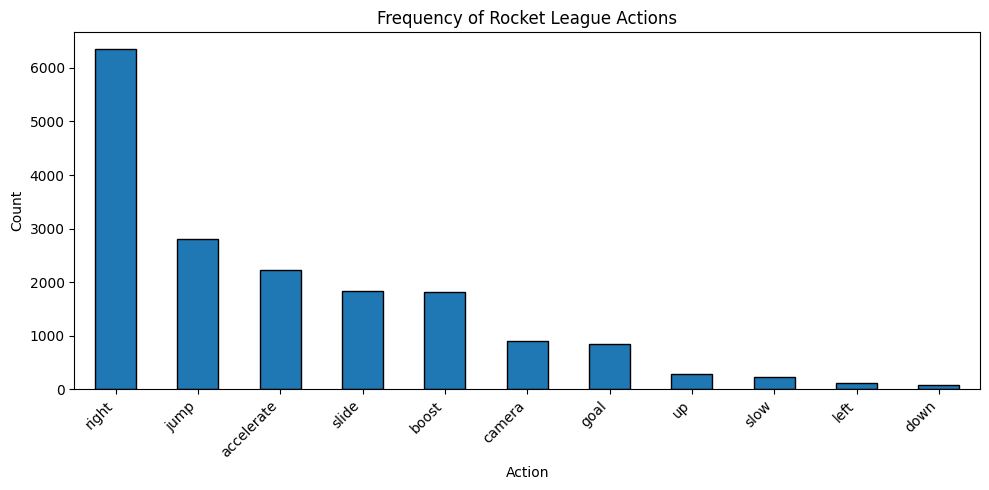

In [7]:
import matplotlib.pyplot as plt

# Count occurrences of each action label
for column in action_columns:
    print(f"\nDistribution for '{column}':")
    display(df_clean[column].value_counts().sort_index())

# Visualize action frequencies
action_counts = df_clean[action_columns].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
action_counts.plot(kind="bar", edgecolor="black")
plt.title("Frequency of Rocket League Actions")
plt.xlabel("Action")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [8]:
from pathlib import Path

output_dir = Path("processed_data")
output_dir.mkdir(exist_ok=True)

output_file = output_dir / "rocket_league_skillshots_cleaned.csv"
df_clean.to_csv(output_file, index=False)

print("Cleaned dataset saved to:", output_file)
print("Final dataset shape:", df_clean.shape)

Cleaned dataset saved to: processed_data\rocket_league_skillshots_cleaned.csv
Final dataset shape: (6892, 18)


## Result

The Rocket League Skillshots dataset was loaded and inspected. The completely empty column was removed, and rows with missing values in the selected gameplay features and action labels were excluded. The distributions of the action columns were examined, and the cleaned dataset was saved as `rocket_league_skillshots_cleaned.csv`.

## Conclusion

The dataset was cleaned and prepared for further feature preparation. Gameplay measurements and action indicators were identified. The next stage will define the classification target and prepare the data for model training and evaluation.